In [1]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, PoissonRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Styling plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load Dataset
df = pd.read_csv("final_data.csv")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (208, 10)


,match_id,date,kickoff_time,team_name,goal_score,xg,confederation,fifa_ranking,elo_rating,team_market_value
0,1,2026-06-11,19:00,Mexico,2,1.84,CONCACAF,14,1810,411906509
1,1,2026-06-11,19:00,South Africa,0,0.52,CAF,60,1620,47700000
2,2,2026-06-11,23:00,South Korea,2,1.45,AFC,22,1800,139050000
3,2,2026-06-11,23:00,Czechia,1,1.12,UEFA,40,1740,187141830
4,3,2026-06-12,19:00,Canada,1,1.35,CONCACAF,33,1795,204233523


,match_id,goal_score,xg,fifa_ranking,elo_rating,team_market_value
count,208.000000,208.000000,208.000000,208.000000,208.000000,2.080000e+02
mean,52.500000,1.480769,1.328462,28.259615,1839.471154,5.134707e+08
std,30.093253,1.393434,0.836834,22.940164,167.936350,5.147272e+08
min,1.000000,0.000000,0.080000,1.000000,1510.000000,3.790570e+07
25%,26.750000,0.000000,0.720000,8.750000,1720.000000,1.454358e+08
50%,52.500000,1.000000,1.150000,22.500000,1817.500000,3.571845e+08
75%,78.250000,2.000000,1.800000,44.250000,1970.000000,6.340660e+08
max,104.000000,7.000000,4.820000,85.000000,2150.000000,2.134173e+09


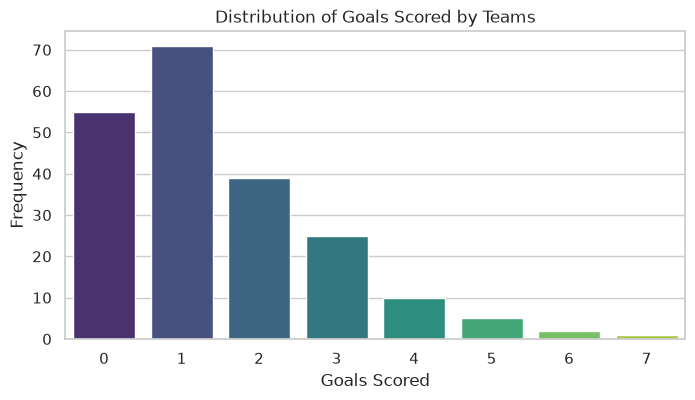

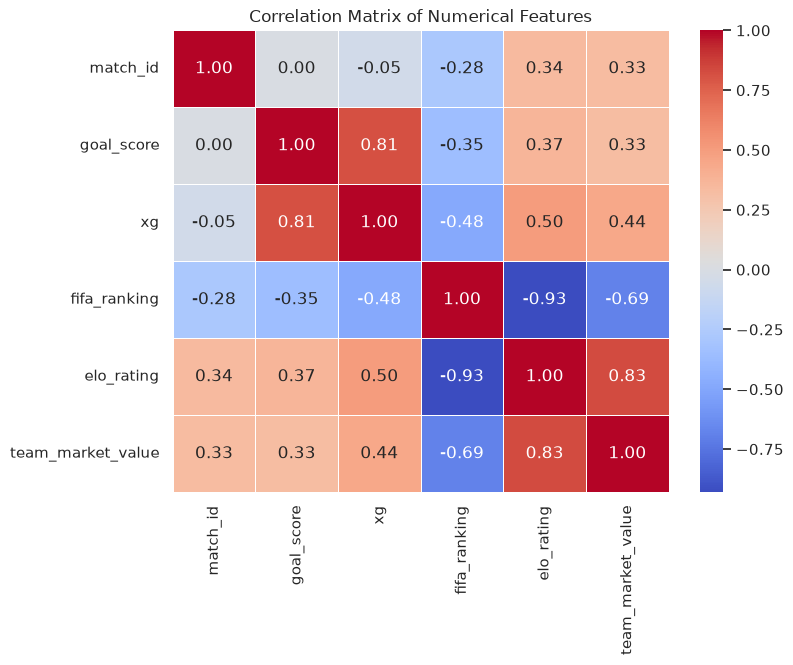

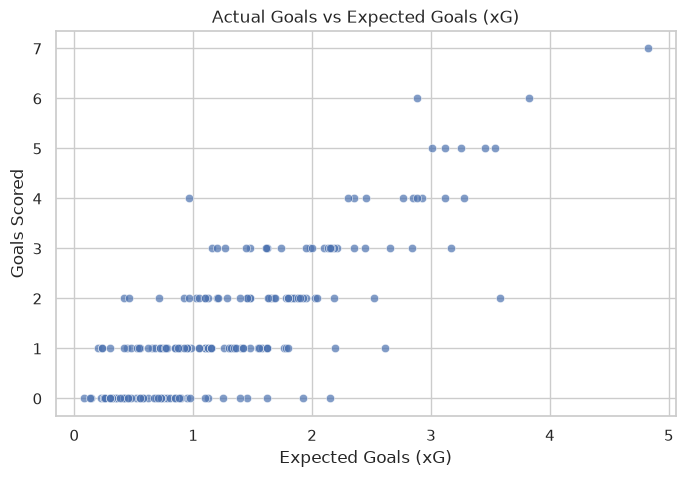

In [2]:
# 1. Summary Statistics of Numerical Features
display(df.describe())

# 2. Target Variable Distribution (Goal Score)
plt.figure(figsize=(8, 4))
sns.countplot(x="goal_score", data=df, palette="viridis")
plt.title("Distribution of Goals Scored by Teams")
plt.xlabel("Goals Scored")
plt.ylabel("Frequency")
plt.show()

# 3. Correlation Matrix (Checking linear patterns)
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(
    df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

# 4. Goals vs xG (Expected Goals) relation
plt.figure(figsize=(8, 5))
sns.scatterplot(x="xg", y="goal_score", data=df, alpha=0.7, color="b")
plt.title("Actual Goals vs Expected Goals (xG)")
plt.xlabel("Expected Goals (xG)")
plt.ylabel("Goals Scored")
plt.show()

In [3]:
# Feature Engineering ideas:
# - Convert date to datetime features (e.g., day of week, month)
# - Log transform team market value since financial data is heavily right-skewed.

df["date"] = pd.to_datetime(df["date"])
df["match_month"] = df["date"].dt.month
df["match_dayofweek"] = df["date"].dt.dayofweek
df["log_market_value"] = np.log1p(df["team_market_value"])

# Define features (X) and target (y)
# Note: xG is strongly correlated with goals. In predictive pipelines before a match starts, xG wouldn't be known (it's post-match metric).
# We can train models WITH xG (if predicting post-match/in-match analysis) and WITHOUT xG (if predicting pre-match).
# Here we'll show with standard features, including or excluding xG depending on your use case.

features_with_xg = [
    "xg",
    "fifa_ranking",
    "elo_rating",
    "log_market_value",
    "confederation",
]
features_pre_match = [
    "fifa_ranking",
    "elo_rating",
    "log_market_value",
    "confederation",
]

# Let's use pre-match features + xG as primary feature set
X = df[
    [
        "xg",
        "fifa_ranking",
        "elo_rating",
        "log_market_value",
        "confederation",
        "match_dayofweek",
    ]
]
y = df["goal_score"]

# Categorical and Numerical columns setup
categorical_cols = ["confederation"]
numerical_cols = [
    c
    for c in X.columns
    if c not in categorical_cols
    and c not in ["match_id", "date", "team_name"]
]

from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


def evaluate_model(model, X_tr, y_tr, X_te, y_te, model_name="Model"):
  # Fit model
  model.fit(X_tr, y_tr)

  # Predictions
  y_pred_train = model.predict(X_tr)
  y_pred_test = model.predict(X_te)

  # Metrics
  rmse_train = np.sqrt(mean_squared_error(y_tr, y_pred_train))
  rmse_test = np.sqrt(mean_squared_error(y_te, y_pred_test))
  mae_test = mean_absolute_error(y_te, y_pred_test)
  r2_test = r2_score(y_te, y_pred_test)

  print(f"=== {model_name} Performance ===")
  print(f"Train RMSE: {rmse_train:.4f}")
  print(f"Test RMSE:  {rmse_test:.4f}")
  print(f"Test MAE:   {mae_test:.4f}")
  print(f"Test R2:    {r2_test:.4f}\n")

  return model, y_pred_test

In [5]:
# 1. Baseline Model (Mean Predictor)
class MeanBaseline:

  def fit(self, X, y):
    self.mean_val = np.mean(y)

  def predict(self, X):
    return np.full(len(X), self.mean_val)


baseline = MeanBaseline()
baseline.fit(X_train, y_train)
base_preds = baseline.predict(X_test)
print(
    f"Baseline Test RMSE: {np.sqrt(mean_squared_error(y_test, base_preds)):.4f}"
)
print("-" * 40)

# 2. Linear Regression / Ridge Regression
ridge_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("regressor", Ridge(alpha=1.0))]
)
evaluate_model(
    ridge_pipeline, X_train, y_train, X_test, y_test, model_name="Ridge Regression"
)

# 3. Poisson Regression (Ideal for count data like goals!)
poisson_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", PoissonRegressor(alpha=1.0, max_iter=500)),
    ]
)
evaluate_model(
    poisson_pipeline,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Poisson Regression",
)

# 4. Random Forest Regressor
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(n_estimators=100, random_state=42),
        ),
    ]
)
evaluate_model(
    rf_pipeline, X_train, y_train, X_test, y_test, model_name="Random Forest"
)

# 5. Gradient Boosting Regressor
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            GradientBoostingRegressor(n_estimators=100, random_state=42),
        ),
    ]
)
evaluate_model(
    gb_pipeline,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Gradient Boosting",
)

Baseline Test RMSE: 1.4184
----------------------------------------
=== Ridge Regression Performance ===
Train RMSE: 0.7619
Test RMSE:  0.9671
Test MAE:   0.7338
Test R2:    0.5330

=== Poisson Regression Performance ===
Train RMSE: 0.8708
Test RMSE:  0.9133
Test MAE:   0.7539
Test R2:    0.5835

=== Random Forest Performance ===
Train RMSE: 0.3387
Test RMSE:  0.9406
Test MAE:   0.6743
Test R2:    0.5582

=== Gradient Boosting Performance ===
Train RMSE: 0.3395
Test RMSE:  0.9833
Test MAE:   0.7170
Test R2:    0.5173



(Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['xg', 'fifa_ranking',
                                                    'elo_rating',
                                                    'log_market_value',
                                                    'match_dayofweek']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore'),
                                                   ['confederation'])])),
                 ('regressor', GradientBoostingRegressor(random_state=42))]),
 array([ 5.10860143,  0.55724429,  0.67822652,  1.15975993,  2.47155139,
         1.74660674,  0.61895783,  1.55316967,  2.81114683,  0.05936027,
         1.14224082,  2.19528853,  0.82008923,  3.44831939,  1.03937944,
         1.94348177,  3.49338765,  0.159919  ,  1.62207806,  3.15071694,
         0.8

In [6]:
# Let's perform Grid Search for Random Forest to find optimal parameters
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "regressor__n_estimators": [50, 100, 200, 300],
    "regressor__max_depth": [None, 3, 5, 10, 15],
    "regressor__min_samples_split": [2, 5, 10],
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)

print("Best Hyperparameters found:", search.best_params_)
best_model = search.best_estimator_

# Evaluate tuned model
evaluate_model(
    best_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Tuned Random Forest",
)

Best Hyperparameters found: {'regressor__n_estimators': 50, 'regressor__min_samples_split': 2, 'regressor__max_depth': 3}
=== Tuned Random Forest Performance ===
Train RMSE: 0.6839
Test RMSE:  0.9607
Test MAE:   0.7516
Test R2:    0.5392



(Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['xg', 'fifa_ranking',
                                                    'elo_rating',
                                                    'log_market_value',
                                                    'match_dayofweek']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore'),
                                                   ['confederation'])])),
                 ('regressor',
                  RandomForestRegressor(max_depth=3, n_estimators=50,
                                        random_state=42))]),
 array([4.87641856, 0.51789441, 0.55363538, 1.3328033 , 2.3797063 ,
        1.75410621, 0.4993649 , 1.58153127, 2.18370881, 0.51051875,
        1.39084371, 1.79010849, 0.4993649 , 3.02549025, 1.74217185,
        1.753524

=== Final Best Model Performance ===
Train RMSE: 0.6839
Test RMSE:  0.9607
Test MAE:   0.7516
Test R2:    0.5392



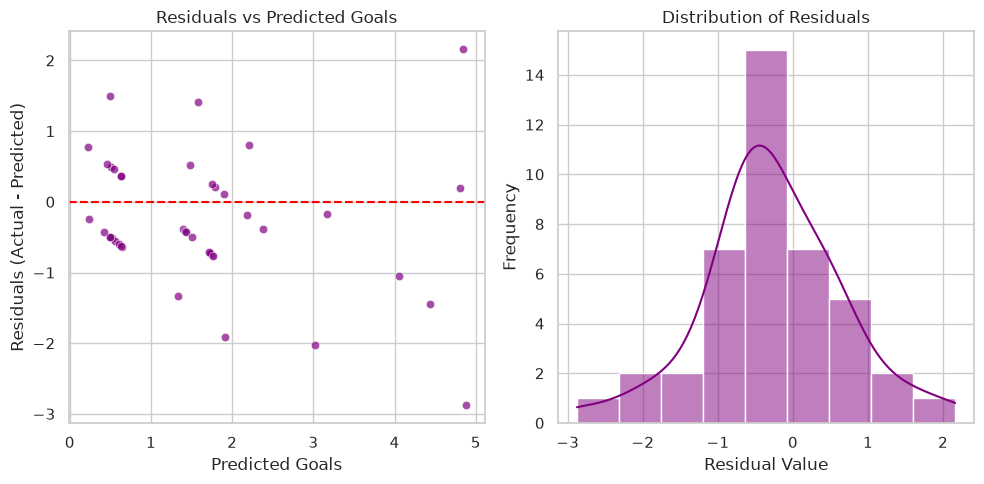

In [7]:
# Get predictions on the test set from our best model
_, final_preds = evaluate_model(
    best_model, X_train, y_train, X_test, y_test, model_name="Final Best Model"
)

# Residual Analysis Plot
residuals = y_test - final_preds

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=final_preds, y=residuals, alpha=0.7, color="purple")
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Goals")
plt.xlabel("Predicted Goals")
plt.ylabel("Residuals (Actual - Predicted)")

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color="purple")
plt.title("Distribution of Residuals")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()